# Set de Predicción


Este notebook realiza la predicción en base a la arquitectura congelada que se obtuvo en el documento *02_entrenamiento.ipynb*. 

El proceso de este notebook es el siguiente:
1. Montar el modelo congelado
2. Ingresar una imagen a predecir
3. El modelo te arroja su predicción junto con la probabilidad por cada clase

### Librerías

In [2]:
import json
import numpy as np
import tensorflow as tf
from pathlib import Path
from tensorflow import keras
import matplotlib.pyplot as plt
from tkinter import Tk, filedialog

2026-11-05 10:14:26.778956: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [3]:
#Rutas
PROJECT_DIR = Path("/Users/sebaschitiva/Desktop/Concentración_IA_Avanzada/Periodo_Avanzado/Proyecto")
MODEL_DIR = PROJECT_DIR / "models"
MODEL_PATH = MODEL_DIR / "brain_tumor_baseline.keras"
CLASS_NAMES_PATH = MODEL_DIR / "class_names.json"

IMG_SIZE = (128, 128)

# Comprobar que existan los archivos
if not MODEL_PATH.exists():
    raise FileNotFoundError(f"No se encontró el modelo: {MODEL_PATH}")

if not CLASS_NAMES_PATH.exists():
    raise FileNotFoundError(f"No se encontró el archivo de clases: {CLASS_NAMES_PATH}")

# Cargar modelo
model = keras.models.load_model(MODEL_PATH)

# Cargar orden de clases
with open(CLASS_NAMES_PATH, "r", encoding="utf-8") as file:
    CLASS_NAMES = json.load(file)

print("Modelo cargado correctamente.")
print("Clases:", CLASS_NAMES)

Modelo cargado correctamente.
Clases: ['glioma', 'meningioma', 'pituitary', 'healthy']


In [ ]:
def predecir_imagen(image_path):

    image_path = Path(image_path)

    if not image_path.exists():
        raise FileNotFoundError(f"No se encontró la imagen: {image_path}")

    # Cargar y adaptar imagen
    image = keras.utils.load_img(
        image_path,
        target_size=IMG_SIZE,
        color_mode="rgb"
    )

    # Preprocesamiento de la imagen
    image_array = keras.utils.img_to_array(image)
    image_array = image_array / 255.0
    image_array = np.expand_dims(image_array, axis=0)

    # Realizar predicción
    predictions = model.predict(image_array, verbose=0)[0]

    # Obtener clase con mayor probabilidad
    predicted_index = np.argmax(predictions)
    predicted_class = CLASS_NAMES[predicted_index]
    confidence = predictions[predicted_index] * 100

    # Mostrar imagen y resultado
    plt.figure(figsize=(5, 5))
    plt.imshow(image)
    plt.axis("off")
    plt.title(
        f"Predicción: {predicted_class}\n"
        f"Confianza: {confidence:.2f}%"
    )
    plt.show()

    print("Resultado de la predicción")
    print("Clase:", predicted_class)
    print(f"Confianza: {confidence:.2f}%")

    print("\nProbabilidades por clase:")

    for class_name, probability in zip(CLASS_NAMES, predictions):
        print(f"{class_name}: {probability * 100:.2f}%")

    return predicted_class, confidence

Imagen seleccionada: glioma995.png


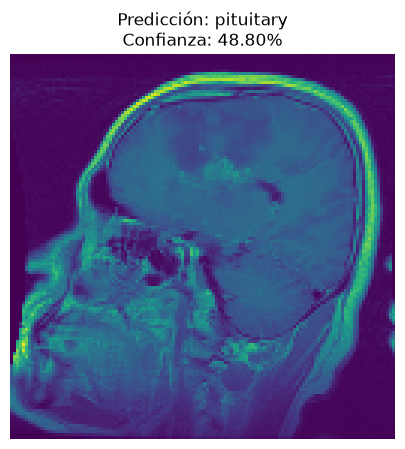

Resultado de la predicción
Clase: pituitary
Confianza: 48.80%

Probabilidades por clase:
glioma: 26.69%
meningioma: 24.46%
pituitary: 48.80%
healthy: 0.06%


In [8]:
# Abrir ventana para seleccionar una imagen
ventana = Tk()
ventana.withdraw()

image_path = filedialog.askopenfilename(
    title="Selecciona una imagen de resonancia",
    filetypes=[
        ("Imágenes", "*.jpg *.jpeg *.png"),
        ("Todos los archivos", "*.*")
    ]
)

ventana.destroy()
print(f"Imagen seleccionada: {Path(image_path).name}")
# Ejecutar predicción
if image_path:
    resultado = predecir_imagen(image_path)
else:
    print("No seleccionaste ninguna imagen.")